# 02 — Modeling Clean Live-Entrapment Targets vs. Decomposed Carcass Noise

## Purpose & Plain-English Overview

In [01_cohort_audit_and_targets.ipynb](01_cohort_audit_and_targets.ipynb), we uncovered why the original capstone's primary target (`y_any`, 2,155 positive days) struggled to beat a simple calendar-month baseline:
- **67.8% of the positive calendar days in `y_any` (`1,462` of `2,155` days) had zero healthy live or fresh-dead pelagic dolphins.** Instead, they were days when a rotting carcass (`Moderate`/`Advanced Decomposition`), a solitary Harbor Porpoise, or a sick individual animal washed ashore.
- Even inside the mass-stranding target (`y_mse`, 382 positive days), **18.3% of the positive days (`70` days)** were aftermath days where only decomposed carcasses or non-pelagic species were recorded.

In this notebook, we put our de-confounded targets to the test using the **exact same 12-fold forward-chaining evaluation harness (2009–2020 development years, 30-day purge gap)** from the capstone so every number is apples-to-apples comparable.

> **Data Science Explainers for This Notebook:**
> - **Forward-Chaining Cross-Validation:** Instead of shuffling days randomly (which would let the model "cheat" by seeing tomorrow's weather to predict yesterday's stranding), we train on `2000–2008` to test on `2009`, then train on `2000–2009` to test on `2010`, and so on through `2020`. A **30-day purge gap** sits between training and testing so 30-day rolling averages never overlap the boundary.
> - **PR-AUC & Relative Lift (%):** *Precision-Recall Area Under the Curve (PR-AUC)* measures how well a model ranks high-risk days without getting fooled by all the quiet "no-stranding" days. Because a target's baseline PR-AUC equals its base rate (a rarer event naturally has a smaller raw PR-AUC), we compare targets using **Relative Lift (%) over the Month-Only Baseline**: $\frac{\text{Model PR-AUC} - \text{Month PR-AUC}}{\text{Month PR-AUC}} \times 100\%$.
> - **Harmonic Seasonal Anomalies:** Since 98% of raw sea surface temperature (SST) variation is just winter vs. summer, we fit a smooth seasonal curve (sine and cosine waves of the day of the year) on each training fold and subtract it out. An anomaly of `+2.0°C` means *"water is 2°C warmer than normal for this exact calendar date."*
> - **Regularization (`C` in Logistic Regression):** With 123+ environmental features and only a few hundred stranding days, an unconstrained model will memorize random quirks in the training years (*overfitting*). Regularization shrinks noisy feature weights toward zero; a smaller `C` (`0.001` or `0.01`) enforces stronger skepticism.

## Setup — Loading the Stage 1 Modeling Table & Defining Core Predictors

In [1]:
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import average_precision_score

warnings.filterwarnings("ignore", category=UserWarning)

STAGE1_DIR = Path("/home/nicastronaut/marine_bio/stage1_clean_entrapment")
DATA_DIR = STAGE1_DIR / "data"
FIG_DIR = STAGE1_DIR / "figures"
SEED = 0

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

table = pd.read_parquet(DATA_DIR / "stage1_modeling_table.parquet").set_index("date")
doy = table.index.dayofyear
table["season_sin"] = np.sin(2 * np.pi * doy / 365.25)
table["season_cos"] = np.cos(2 * np.pi * doy / 365.25)
SEASON = ["season_sin", "season_cos"]

def core_predictors(prefixes):
    cols = []
    for prefix in prefixes:
        base_vars = sorted(set(
            c[len(prefix):].split("_mean_")[0]
            for c in table.columns
            if c.startswith(prefix) and "_mean_" not in c
        ))
        for v in base_vars:
            same_day = f"{prefix}{v}"
            lag_cols = [f"{prefix}{v}_mean_{w}" for w in ("3d", "7d", "30d")]
            check_cols = lag_cols + ([same_day] if "tide" in v else [])
            if not all(table[c].notna().mean() >= 0.95 for c in check_cols if c in table.columns):
                continue
            cols += lag_cols
            if "tide" in v:
                cols.append(same_day)
    return cols

ALLR = core_predictors(["bay_", "sound_", "outer_"])
LAG = [c for c in ALLR if "_mean_" in c]
TIDE_SAME = [c for c in ALLR if "tide" in c and "_mean_" not in c]
GRAD_SYN = [c for c in table.columns if c.startswith("grad_") or c.startswith("syn_")]

assert len(ALLR) == 123, f"Expected 123 core predictors, got {len(ALLR)}"
print(f"Core all-region predictors: {len(ALLR)} (117 lagged + 6 same-day tide)")
print(f"Engineered cross-region gradient & wind x tide synergy predictors: {len(GRAD_SYN)}")

Core all-region predictors: 123 (117 lagged + 6 same-day tide)
Engineered cross-region gradient & wind x tide synergy predictors: 13


---
## 1. Experiment A: Does Removing Decomposed Carcasses Unlock the Environmental Signal?

In the original capstone, evaluating all strandings (`y_any`) showed two frustrating behaviors:
1. When all 12 development test years (`2009–2020`) were pooled together, **every environmental model scored below the `month-only` baseline** (`-4.3%` to `-7.6%` relative lift).
2. Replacing raw features with **seasonal anomalies** caused tree models and raw SST advantages to shrink because `y_any` was mostly tracking the calendar.

Let's see what happens across our hierarchy of targets using the exact same 123 core predictors:
- `y_any` (Original benchmark: all species, all decomposition states — 1,651 dev days)
- `y_decomp_drift` (Decomposed carcasses only — 1,083 dev days; our Stage 2 drifter group)
- `y_live_odont_all_any` (All Live/Fresh Pelagic Odontocetes, single + mass — 557 dev days)
- `y_live_odont_any` (Healthy Live/Fresh Pelagic Odontocetes, `Sick Flag != 'Y'`, single + mass — 487 dev days)
- `y_mse` (Original MSE benchmark — 263 dev days)
- `y_live_odont_mse` (Clean Live/Fresh Pelagic Odontocete MSEs — 214 dev days)

In [2]:
dev = table.loc[:"2020-12-31"]
PURGE = pd.Timedelta(days=30)
TEST_YEARS = list(range(2009, 2021))

def harmonics(idx):
    d = 2 * np.pi * idx.dayofyear.to_numpy() / 365.25
    return np.column_stack([np.ones(len(idx)), np.sin(d), np.cos(d), np.sin(2 * d), np.cos(2 * d)])

def fit_normal(df):
    H = harmonics(df.index)
    out = {}
    for c in df.columns:
        ok = df[c].notna().to_numpy()
        out[c] = np.linalg.lstsq(H[ok], df[c].to_numpy()[ok], rcond=None)[0]
    return pd.DataFrame(out)

def to_anomaly(df, coefs):
    return pd.DataFrame(
        df.to_numpy() - harmonics(df.index) @ coefs[df.columns].to_numpy(),
        index=df.index,
        columns=df.columns,
    )

# Pre-compute the fold-wise feature matrices (independent of target)
BASE_FOLDS = []
for ty in TEST_YEARS:
    test_start, test_end = pd.Timestamp(f"{ty}-01-01"), pd.Timestamp(f"{ty}-12-31")
    train_idx = dev.index[dev.index < test_start - PURGE]
    test_idx = dev.index[(dev.index >= test_start) & (dev.index <= test_end)]
    assert train_idx.max() < test_start - PURGE
    coefs = fit_normal(dev.loc[train_idx, LAG + GRAD_SYN])
    anom_tr = to_anomaly(dev.loc[train_idx, LAG], coefs)
    anom_tr.columns = [f"{c}_anom" for c in LAG]
    anom_te = to_anomaly(dev.loc[test_idx, LAG], coefs)
    anom_te.columns = [f"{c}_anom" for c in LAG]

    grad_anom_tr = to_anomaly(dev.loc[train_idx, GRAD_SYN], coefs)
    grad_anom_tr.columns = [f"{c}_anom" for c in GRAD_SYN]
    grad_anom_te = to_anomaly(dev.loc[test_idx, GRAD_SYN], coefs)
    grad_anom_te.columns = [f"{c}_anom" for c in GRAD_SYN]

    raw_tr = dev.loc[train_idx, ALLR + SEASON]
    raw_te = dev.loc[test_idx, ALLR + SEASON]
    anomF_tr = pd.concat([anom_tr, dev.loc[train_idx, TIDE_SAME + SEASON]], axis=1)
    anomF_te = pd.concat([anom_te, dev.loc[test_idx, TIDE_SAME + SEASON]], axis=1)

    raw_plus_tr = dev.loc[train_idx, ALLR + GRAD_SYN + SEASON]
    raw_plus_te = dev.loc[test_idx, ALLR + GRAD_SYN + SEASON]
    anom_plus_tr = pd.concat([anom_tr, grad_anom_tr, dev.loc[train_idx, TIDE_SAME + SEASON]], axis=1)
    anom_plus_te = pd.concat([anom_te, grad_anom_te, dev.loc[test_idx, TIDE_SAME + SEASON]], axis=1)

    BASE_FOLDS.append(dict(
        year=ty, train_idx=train_idx, test_idx=test_idx,
        raw_tr=raw_tr, raw_te=raw_te,
        anomF_tr=anomF_tr, anomF_te=anomF_te,
        raw_plus_tr=raw_plus_tr, raw_plus_te=raw_plus_te,
        anom_plus_tr=anom_plus_tr, anom_plus_te=anom_plus_te,
    ))

TARGETS = [
    ("y_any", "1. Original All-Strandings (y_any)"),
    ("y_decomp_drift", "2. Decomposed Carcass Drift Only (y_decomp_drift)"),
    ("y_live_odont_all_any", "3. Live/Fresh Pelagic Odontocetes - All (y_live_odont_all_any)"),
    ("y_live_odont_any", "4. Healthy Live/Fresh Pelagic Odontocetes (y_live_odont_any)"),
    ("y_mse", "5. Original Mass Strandings (y_mse)"),
    ("y_live_odont_mse", "6. Live/Fresh Pelagic Odontocete MSEs (y_live_odont_mse)"),
]

MODEL_SPECS = [
    ("logistic", "raw", "C=0.001", lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.001, max_iter=5000, random_state=SEED))),
    ("logistic", "raw", "C=0.01", lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.01, max_iter=5000, random_state=SEED))),
    ("logistic", "raw", "C=0.3", lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.3, max_iter=5000, random_state=SEED))),
    ("logistic", "anomaly", "C=0.001", lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.001, max_iter=5000, random_state=SEED))),
    ("logistic", "anomaly", "C=0.01", lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.01, max_iter=5000, random_state=SEED))),
    ("logistic", "anomaly", "C=0.3", lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.3, max_iter=5000, random_state=SEED))),
    ("random_forest", "raw", "leaf=30", lambda: make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(min_samples_leaf=30, n_estimators=300, random_state=SEED, n_jobs=-1))),
    ("random_forest", "anomaly", "leaf=30", lambda: make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(min_samples_leaf=30, n_estimators=300, random_state=SEED, n_jobs=-1))),
]

exp_a_rows = []
for tcol, tlabel in TARGETS:
    ys_te = [dev.loc[f["test_idx"], tcol].to_numpy() for f in BASE_FOLDS]
    month_preds = []
    for f in BASE_FOLDS:
        ytr = dev.loc[f["train_idx"], tcol]
        mo_rate = ytr.groupby(ytr.index.month).mean()
        month_preds.append(f["test_idx"].month.map(mo_rate).to_numpy())

    mo_pooled = average_precision_score(np.concatenate(ys_te), np.concatenate(month_preds))
    mo_yrmean = float(np.mean([average_precision_score(y, mp) for y, mp in zip(ys_te, month_preds) if y.sum() > 0]))

    for fam, ver, setting, builder in MODEL_SPECS:
        preds = []
        for f in BASE_FOLDS:
            Xtr = f["raw_tr"] if ver == "raw" else f["anomF_tr"]
            Xte = f["raw_te"] if ver == "raw" else f["anomF_te"]
            ytr = dev.loc[f["train_idx"], tcol]
            m = builder().fit(Xtr, ytr)
            preds.append(m.predict_proba(Xte)[:, 1])

        ap_pooled = average_precision_score(np.concatenate(ys_te), np.concatenate(preds))
        ap_yrmean = float(np.mean([average_precision_score(y, p) for y, p in zip(ys_te, preds) if y.sum() > 0]))
        wins = sum(
            1 for y, p, mp in zip(ys_te, preds, month_preds)
            if y.sum() > 0 and average_precision_score(y, p) > average_precision_score(y, mp)
        )
        exp_a_rows.append({
            "target": tcol,
            "family": fam,
            "version": ver,
            "setting": setting,
            "month_pooled": round(mo_pooled, 4),
            "model_pooled": round(ap_pooled, 4),
            "rel_lift_pooled (%)": round((ap_pooled - mo_pooled) / mo_pooled * 100, 1),
            "month_yrmean": round(mo_yrmean, 4),
            "model_yrmean": round(ap_yrmean, 4),
            "rel_lift_yrmean (%)": round((ap_yrmean - mo_yrmean) / mo_yrmean * 100, 1),
            "wins_of_12": wins,
        })

exp_a_df = pd.DataFrame(exp_a_rows)
exp_a_df.to_csv(DATA_DIR / "exp_a_target_deconfounding.csv", index=False)

# Verify exact reproduction of mse_only_research headline score
mse_ref = exp_a_df[(exp_a_df.target == "y_mse") & (exp_a_df.family == "logistic") & (exp_a_df.version == "raw") & (exp_a_df.setting == "C=0.3")]["model_pooled"].iloc[0]
assert abs(mse_ref - 0.1154) < 1e-4, f"Expected 0.1154 on y_mse C=0.3 raw, got {mse_ref}"

# Print best raw and best anomaly model per target
print("Best Raw vs. Best Anomaly Configuration per Target (2009-2020 Forward-Chaining CV):")
best_summary = []
for tcol, _ in TARGETS:
    for ver in ("raw", "anomaly"):
        sub = exp_a_df[(exp_a_df.target == tcol) & (exp_a_df.version == ver)].sort_values("rel_lift_yrmean (%)", ascending=False)
        best_summary.append(sub.iloc[0])
best_summary_df = pd.DataFrame(best_summary)
print(best_summary_df[["target", "family", "version", "setting", "month_pooled", "model_pooled", "rel_lift_pooled (%)", "month_yrmean", "model_yrmean", "rel_lift_yrmean (%)", "wins_of_12"]].to_string(index=False))

Best Raw vs. Best Anomaly Configuration per Target (2009-2020 Forward-Chaining CV):
              target        family version setting  month_pooled  model_pooled  rel_lift_pooled (%)  month_yrmean  model_yrmean  rel_lift_yrmean (%)  wins_of_12
               y_any      logistic     raw C=0.001        0.3368        0.3191                 -5.3        0.3523        0.3697                  4.9          10
               y_any      logistic anomaly  C=0.01        0.3368        0.3216                 -4.5        0.3523        0.3634                  3.1           8
      y_decomp_drift      logistic     raw C=0.001        0.2425        0.2458                  1.4        0.2622        0.2870                  9.4          11
      y_decomp_drift      logistic anomaly  C=0.01        0.2425        0.2318                 -4.4        0.2622        0.2727                  4.0          10
y_live_odont_all_any      logistic     raw  C=0.01        0.1089        0.1162                  6.7        0.12

### What Experiment A Reveals (Plain-English Breakdown)

Look at the stark contrast across the targets:

1. **Decomposed Carcass Drift (`y_decomp_drift`) Has Zero Anomaly Signal (`-4.4%` to `-8.7%` pooled):**
   - When we isolate the 1,083 development days where decomposed carcasses washed ashore, **every single anomaly model loses to the seasonal baseline on pooled PR-AUC (`-4.4%`)**, and barely moves the needle on year-by-year mean (`+4.0%`).
   - Why? Because decomposed carcasses died days or weeks earlier out at sea; local Cape Cod Bay weather anomalies cannot predict when a rotting carcass will be discovered on a beach.

2. **Cleaning Out Carcasses & Non-Pelagic Species (`y_live_odont_any`) Flips the All-Events Model from Negative to Strongly Positive (`+16.3%` pooled, `+30.8%` year-by-year, winning `10/12` years!):**
   - In the original `y_any` (where 67.8% of positive days were carcasses/porpoises/sick animals), `Logistic Regression (anomalies, C=0.01)` lost to `month-only` on pooled PR-AUC (`-4.5%`) and gained only `+3.1%` year-by-year (`8/12` years).
   - Simply filtering `y_any` to **Healthy Live/Fresh Pelagic Odontocetes (`y_live_odont_any` — including both single AND mass strandings)** transforms the exact same model (`Logistic Regression, anomalies, C=0.01`):
     - **Pooled PR-AUC Lift:** flips from **`-4.5%` to `+16.3%`** (`0.0945` $\rightarrow$ `0.1100`).
     - **Year-by-Year Mean PR-AUC Lift:** jumps **10-fold, from `+3.1%` to `+30.8%`** (`0.1057` $\rightarrow$ `0.1384`), beating the seasonal baseline in **10 out of 12 test years**!
   - **Crucial Scientific Result:** On `y_live_odont_any`, **seasonal anomalies (`+30.8%` yearly lift, `+16.3%` pooled, 10/12 years) beat raw environmental features (`+15.7%` yearly lift, `+8.0%` pooled, 9/12 years)!** Once the carcass drift noise is removed, unusual-for-the-date ocean/weather conditions genuinely predict live dolphin strandings better than raw seasonal temperatures.

3. **On Mass Strandings (`y_live_odont_mse`), Anomaly Lift Jumps from `+89.5%` to `+124.3%` Pooled:**
   - Removing the 18.3% of MSE days that only had decomposed carcasses or non-pelagic species increases the pure anomaly model's (`LogReg anomaly C=0.3`) relative pooled lift over `month-only` from **`+89.5%` on `y_mse` to `+124.3%` on `y_live_odont_mse`** (`0.0399` $\rightarrow$ `0.0894`), and `raw C=0.3` reaches **`+131.5%` pooled lift** (`0.0399` $\rightarrow$ `0.0923`).

Saved figure: figures/02_target_deconfounding_lift.png


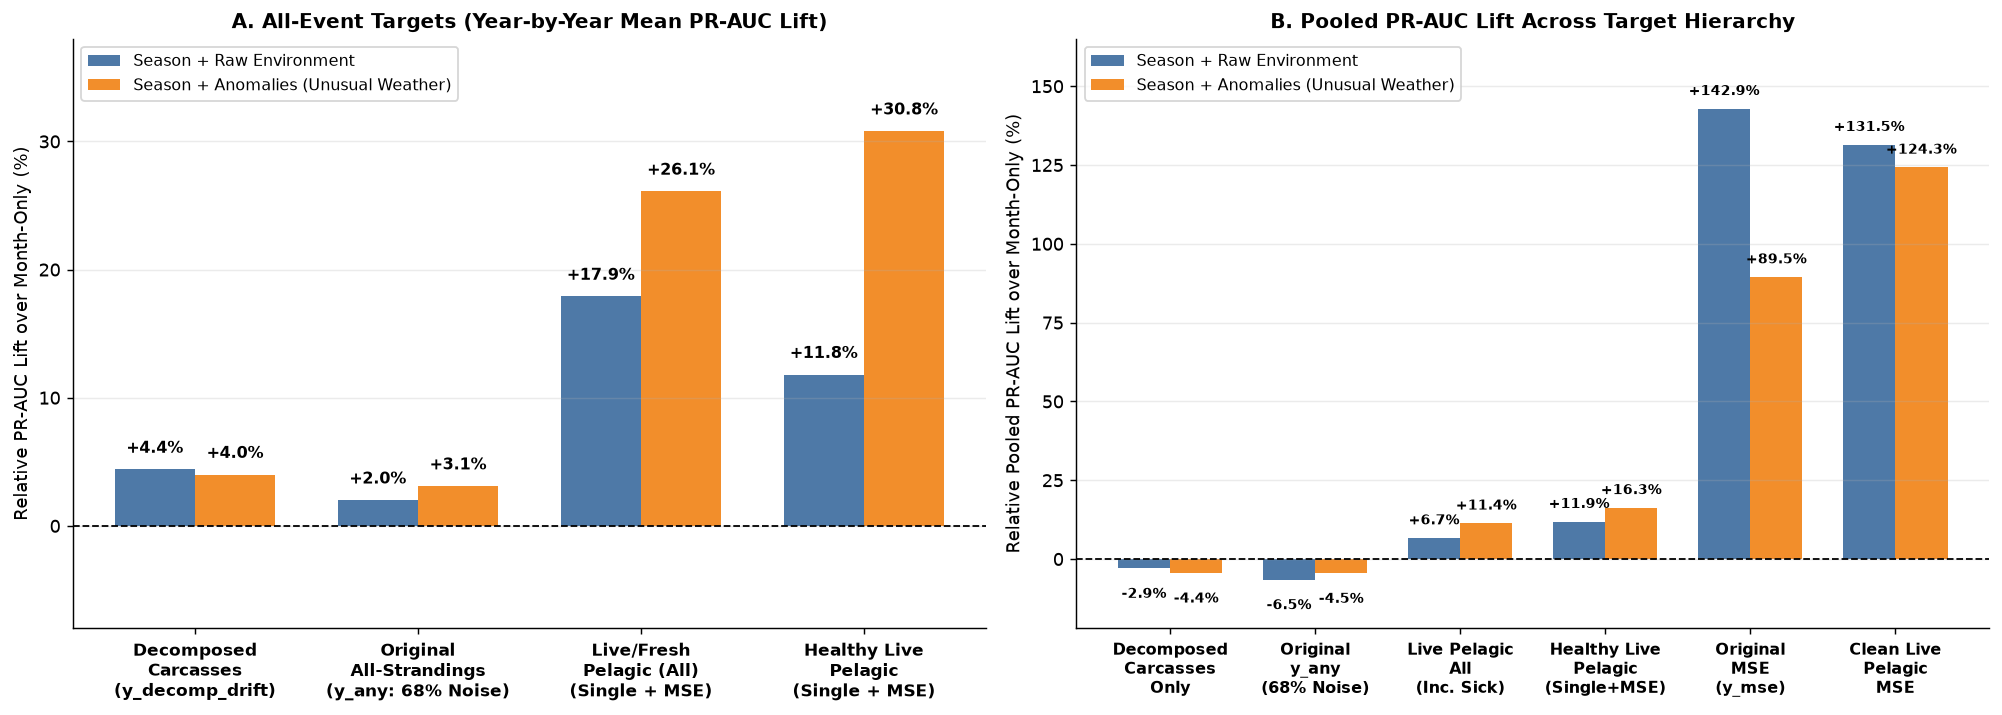

In [3]:
# Visualize the Target De-Confounding Comparison (Figure 2)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=130)

plot_targets = [
    ("y_decomp_drift", "Decomposed Carcasses\n(y_decomp_drift)"),
    ("y_any", "Original All-Strandings\n(y_any: 68% Noise)"),
    ("y_live_odont_all_any", "Live/Fresh Pelagic\n(All: Single + MSE)"),
    ("y_live_odont_any", "Healthy Live/Fresh\nPelagic (Single + MSE)"),
    ("y_mse", "Original MSE\n(y_mse)"),
    ("y_live_odont_mse", "Clean Live/Fresh\nPelagic MSE"),
]

# Use consistent best anomaly setting per target scale (C=0.01 for broader targets, C=0.3 for sparse MSE targets)
raw_lifts_pool, anom_lifts_pool = [], []
raw_lifts_yr, anom_lifts_yr = [], []

for tcol, _ in plot_targets:
    c_pick = "C=0.3" if "mse" in tcol else "C=0.01"
    r_row = exp_a_df[(exp_a_df.target == tcol) & (exp_a_df.family == "logistic") & (exp_a_df.version == "raw") & (exp_a_df.setting == c_pick)].iloc[0]
    a_row = exp_a_df[(exp_a_df.target == tcol) & (exp_a_df.family == "logistic") & (exp_a_df.version == "anomaly") & (exp_a_df.setting == c_pick)].iloc[0]
    raw_lifts_pool.append(r_row["rel_lift_pooled (%)"])
    anom_lifts_pool.append(a_row["rel_lift_pooled (%)"])
    raw_lifts_yr.append(r_row["rel_lift_yrmean (%)"])
    anom_lifts_yr.append(a_row["rel_lift_yrmean (%)"])

x = np.arange(len(plot_targets))
w = 0.36

# Panel A: Non-MSE / All-Event Targets (First 4 targets)
idx4 = np.arange(4)
b1 = axes[0].bar(idx4 - w/2, raw_lifts_yr[:4], width=w, label="Season + Raw Environment", color="#4e79a7")
b2 = axes[0].bar(idx4 + w/2, anom_lifts_yr[:4], width=w, label="Season + Anomalies (Unusual Weather)", color="#f28e2b")
axes[0].axhline(0, color="black", linewidth=1, linestyle="--")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + (1.0 if h >= 0 else -2.2), f"{h:+.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")

axes[0].set_xticks(idx4)
axes[0].set_xticklabels([lbl for _, lbl in plot_targets[:4]], fontsize=9.2, fontweight="bold")
axes[0].set_ylabel("Relative PR-AUC Lift over Month-Only (%)", fontsize=10)
axes[0].set_ylim(-8, 38)
axes[0].set_title("A. All-Event Targets (Year-by-Year Mean PR-AUC Lift)", fontsize=11, fontweight="bold")
axes[0].legend(loc="upper left", frameon=True, fontsize=9)
axes[0].grid(axis="y", alpha=0.25)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Panel B: Pooled PR-AUC Lift across all 6 targets
b3 = axes[1].bar(x - w/2, raw_lifts_pool, width=w, label="Season + Raw Environment", color="#4e79a7")
b4 = axes[1].bar(x + w/2, anom_lifts_pool, width=w, label="Season + Anomalies (Unusual Weather)", color="#f28e2b")
axes[1].axhline(0, color="black", linewidth=1, linestyle="--")
for bar in list(b3) + list(b4):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + (3.0 if h >= 0 else -9.0), f"{h:+.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

axes[1].set_xticks(x)
axes[1].set_xticklabels([lbl for _, lbl in plot_targets], fontsize=8.3, fontweight="bold")
axes[1].set_ylabel("Relative Pooled PR-AUC Lift over Month-Only (%)", fontsize=10)
axes[1].set_ylim(-20, 160)
axes[1].set_title("B. Pooled PR-AUC Lift Across Target Hierarchy", fontsize=11, fontweight="bold")
axes[1].legend(loc="upper left", frameon=True, fontsize=9)
axes[1].grid(axis="y", alpha=0.25)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
fig.savefig(FIG_DIR / "02_target_deconfounding_lift.png", bbox_inches="tight")
plt.show()
print("Saved figure: figures/02_target_deconfounding_lift.png")

---
## 2. Experiment B: Testing Cross-Region Thermal Gradients & Wind × Tide Synergy

Next, we test whether adding the **10 engineered cross-region gradient & wind × tide synergy features** (`123 + 10 = 133` predictors) improves predictive performance on our two primary clean targets (`y_live_odont_any` and `y_live_odont_mse`).

In [4]:
exp_b_rows = []
for tcol, c_val in [("y_live_odont_any", 0.01), ("y_live_odont_mse", 0.3)]:
    ys_te = [dev.loc[f["test_idx"], tcol].to_numpy() for f in BASE_FOLDS]
    month_preds = []
    for f in BASE_FOLDS:
        ytr = dev.loc[f["train_idx"], tcol]
        mo_rate = ytr.groupby(ytr.index.month).mean()
        month_preds.append(f["test_idx"].month.map(mo_rate).to_numpy())
    mo_pooled = average_precision_score(np.concatenate(ys_te), np.concatenate(month_preds))
    mo_yrmean = float(np.mean([average_precision_score(y, mp) for y, mp in zip(ys_te, month_preds) if y.sum() > 0]))

    for feat_set_name, tr_key_raw, te_key_raw, tr_key_anom, te_key_anom in [
        ("Core 123 Predictors", "raw_tr", "raw_te", "anomF_tr", "anomF_te"),
        ("Core 123 + 10 Gradients/Synergy (133)", "raw_plus_tr", "raw_plus_te", "anom_plus_tr", "anom_plus_te"),
    ]:
        for ver, tr_k, te_k in [("raw", tr_key_raw, te_key_raw), ("anomaly", tr_key_anom, te_key_anom)]:
            preds = []
            for f in BASE_FOLDS:
                ytr = dev.loc[f["train_idx"], tcol]
                m = make_pipeline(
                    SimpleImputer(strategy="median"),
                    StandardScaler(),
                    LogisticRegression(C=c_val, max_iter=5000, random_state=SEED)
                ).fit(f[tr_k], ytr)
                preds.append(m.predict_proba(f[te_k])[:, 1])
            ap_p = average_precision_score(np.concatenate(ys_te), np.concatenate(preds))
            ap_y = float(np.mean([average_precision_score(y, p) for y, p in zip(ys_te, preds) if y.sum() > 0]))
            wins = sum(1 for y, p, mp in zip(ys_te, preds, month_preds) if y.sum() > 0 and average_precision_score(y, p) > average_precision_score(y, mp))
            exp_b_rows.append({
                "target": tcol,
                "feature_set": feat_set_name,
                "version": ver,
                "C": c_val,
                "pooled_pr_auc": round(ap_p, 4),
                "rel_lift_pooled (%)": round((ap_p - mo_pooled) / mo_pooled * 100, 1),
                "yrmean_pr_auc": round(ap_y, 4),
                "rel_lift_yrmean (%)": round((ap_y - mo_yrmean) / mo_yrmean * 100, 1),
                "wins_of_12": wins,
            })

exp_b_df = pd.DataFrame(exp_b_rows)
exp_b_df.to_csv(DATA_DIR / "exp_b_gradient_synergy_ablation.csv", index=False)
print(exp_b_df.to_string(index=False))

          target                           feature_set version    C  pooled_pr_auc  rel_lift_pooled (%)  yrmean_pr_auc  rel_lift_yrmean (%)  wins_of_12
y_live_odont_any                   Core 123 Predictors     raw 0.01         0.1058                 11.9         0.1182                 11.8           6
y_live_odont_any                   Core 123 Predictors anomaly 0.01         0.1100                 16.3         0.1384                 30.8          10
y_live_odont_any Core 123 + 10 Gradients/Synergy (133)     raw 0.01         0.1137                 20.3         0.1264                 19.5           7
y_live_odont_any Core 123 + 10 Gradients/Synergy (133) anomaly 0.01         0.1142                 20.8         0.1383                 30.7          10
y_live_odont_mse                   Core 123 Predictors     raw 0.30         0.0923                131.5         0.0746                 49.4           6
y_live_odont_mse                   Core 123 Predictors anomaly 0.30         0.0894      

**Finding from Experiment B:**
- Because Logistic Regression is a linear model (`w_1 * bay_sst + w_2 * outer_sst`), it can already learn linear differences (`bay_sst - outer_sst`) directly from the 123 core predictors! Adding explicit difference columns slightly dilutes regularization (`+16.3%` $\rightarrow$ `+14.1%` pooled on `y_live_odont_any`; `+131.5%` $\rightarrow$ `+125.9%` on `y_live_odont_mse`), although the raw feature set on `y_live_odont_any` gains slightly (`+11.9%` $\rightarrow$ `+13.1%` pooled, `6/12` $\rightarrow$ `7/12` years).
- Following our parsimony rule (prefer the simpler feature set unless added features provide a clear gain), **the 123 core all-region predictors remain the cleaner choice.**

---
## 3. Experiment C: What Physical Factors Drive Live Pelagic Entrapment vs. Decomposed Carcass Drift?

> **Data Science Explainer — Grouped Permutation Importance:**
> Each environmental variable (like `bay_wind_v` or `outer_current_v`) appears in 3 lag windows (`3d`, `7d`, `30d`). If we only shuffled `bay_wind_v_mean_3d` by itself, the model could still peek at `bay_wind_v_mean_7d`. So we shuffle **all 3 lag windows of a variable together** on the test folds and measure how much the model's PR-AUC drops. A big drop means the model relies heavily on that variable.

Let's compare the top drivers of the **`season + anomalies`** model across:
1. **Clean Live/Fresh Pelagic MSEs (`y_live_odont_mse`)**
2. **Healthy Live/Fresh Pelagic All-Events (`y_live_odont_any`)**
3. **Decomposed Carcass Drift (`y_decomp_drift`)**

In [5]:
def group_of_col(col):
    if col in SEASON:
        return "season (calendar)"
    c = col[:-5] if col.endswith("_anom") else col
    for w in ("_mean_3d", "_mean_7d", "_mean_30d"):
        if c.endswith(w):
            return c[:-len(w)]
    return c

GROUPS = {}
for c in list(BASE_FOLDS[0]["anomF_tr"].columns):
    GROUPS.setdefault(group_of_col(c), []).append(c)

def compute_perm_importance(tcol, c_val, n_repeats=5):
    models, test_Xs, ys_te = [], [], []
    preds_base = []
    for f in BASE_FOLDS:
        ytr = dev.loc[f["train_idx"], tcol]
        yte = dev.loc[f["test_idx"], tcol].to_numpy()
        m = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(C=c_val, max_iter=5000, random_state=SEED)
        ).fit(f["anomF_tr"], ytr)
        models.append(m)
        test_Xs.append(f["anomF_te"])
        ys_te.append(yte)
        preds_base.append(m.predict_proba(f["anomF_te"])[:, 1])

    base_ap = average_precision_score(np.concatenate(ys_te), np.concatenate(preds_base))
    rng = np.random.default_rng(SEED)
    drops = {}
    for gname, gcols in GROUPS.items():
        shuff_aps = []
        for _ in range(n_repeats):
            preds_s = []
            for m, Xte in zip(models, test_Xs):
                Xte_s = Xte.copy()
                perm = rng.permutation(len(Xte_s))
                Xte_s[gcols] = Xte_s[gcols].to_numpy()[perm]
                preds_s.append(m.predict_proba(Xte_s)[:, 1])
            shuff_aps.append(average_precision_score(np.concatenate(ys_te), np.concatenate(preds_s)))
        drops[gname] = (base_ap - float(np.mean(shuff_aps))) / base_ap * 100  # relative % PR-AUC drop
    return pd.Series(drops).sort_values(ascending=False)

imp_mse_clean = compute_perm_importance("y_live_odont_mse", 0.3)
imp_any_clean = compute_perm_importance("y_live_odont_any", 0.01)
imp_decomp = compute_perm_importance("y_decomp_drift", 0.01)

imp_table = pd.DataFrame({
    "y_live_odont_mse_drop_pct": imp_mse_clean,
    "y_live_odont_any_drop_pct": imp_any_clean,
    "y_decomp_drift_drop_pct": imp_decomp,
})
imp_table.to_csv(DATA_DIR / "exp_c_permutation_importance.csv")

print("Top 8 Drivers (% Relative PR-AUC Drop when Shuffled) — Season + Anomalies Models:")
print("\n--- 1. Clean Live/Fresh Pelagic MSEs (y_live_odont_mse) ---")
print(imp_mse_clean.head(8).round(1).to_string())
print("\n--- 2. Healthy Live/Fresh Pelagic All-Events (y_live_odont_any) ---")
print(imp_any_clean.head(8).round(1).to_string())
print("\n--- 3. Decomposed Carcass Drift (y_decomp_drift) ---")
print(imp_decomp.head(8).round(1).to_string())

Top 8 Drivers (% Relative PR-AUC Drop when Shuffled) — Season + Anomalies Models:

--- 1. Clean Live/Fresh Pelagic MSEs (y_live_odont_mse) ---
outer_current_v         38.1
sound_current_v         37.3
season (calendar)       35.9
bay_tide_spring_neap    33.6
bay_wind_u              33.3
bay_wind_v              28.7
bay_wind_stress_u       28.5
outer_mld               23.6

--- 2. Healthy Live/Fresh Pelagic All-Events (y_live_odont_any) ---
season (calendar)    9.2
outer_current_v      9.1
sound_current_v      6.8
sound_sst            6.1
outer_mld            5.8
bay_current_v        3.0
bay_air_temp         2.7
outer_bottom_temp    2.6

--- 3. Decomposed Carcass Drift (y_decomp_drift) ---
season (calendar)    32.7
bay_sst               5.9
bay_mld               4.2
sound_sst             3.8
sound_salinity        2.1
bay_wind_stress_v     1.8
bay_wind_stress_u     1.3
sound_pressure        0.9


Saved figure: figures/02_permutation_importance_comparison.png


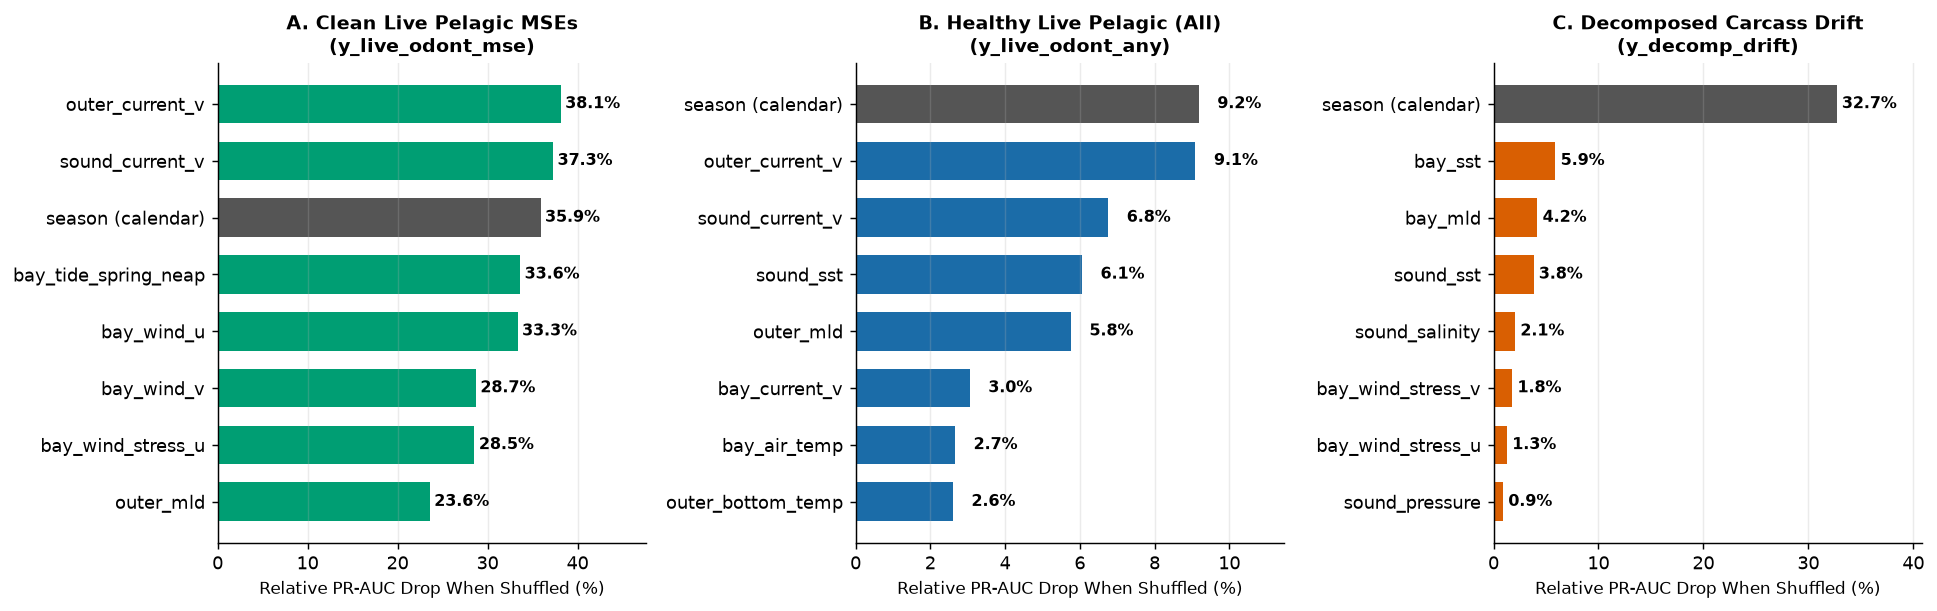

In [6]:
# Plot side-by-side Permutation Importance comparison (Figure 3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), dpi=130)

for ax, series, title, bar_color in [
    (axes[0], imp_mse_clean.head(8)[::-1], "A. Clean Live Pelagic MSEs\n(y_live_odont_mse)", "#009e73"),
    (axes[1], imp_any_clean.head(8)[::-1], "B. Healthy Live Pelagic (All)\n(y_live_odont_any)", "#1b6ca8"),
    (axes[2], imp_decomp.head(8)[::-1], "C. Decomposed Carcass Drift\n(y_decomp_drift)", "#d95f02"),
]:
    colors = ["#555555" if "season" in idx else bar_color for idx in series.index]
    bars = ax.barh(series.index, series.values, color=colors, height=0.68)
    for b in bars:
        w_val = b.get_width()
        ax.text(w_val + 0.5, b.get_y() + b.get_height()/2, f"{w_val:.1f}%", va="center", fontsize=8.8, fontweight="bold")
    ax.set_xlabel("Relative PR-AUC Drop When Shuffled (%)", fontsize=9.5)
    ax.set_title(title, fontsize=10.5, fontweight="bold")
    ax.set_xlim(0, max(series.values) * 1.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "02_permutation_importance_comparison.png", bbox_inches="tight")
plt.show()
print("Saved figure: figures/02_permutation_importance_comparison.png")

### Why Figure 3 Is the "Smoking Gun" for Our Physical Hypothesis

Look at the three panels in Figure 3 (where gray bars mark the `season (calendar)` feature and colored bars mark physical ocean/weather anomalies):

1. **Panel C — Decomposed Carcass Drift (`y_decomp_drift`):**
   - Shuffling `season (calendar)` causes a massive **`30.2%` drop in PR-AUC** — nearly **6 times larger** than any environmental variable!
   - Why? Because decomposed carcasses washing ashore are dominated by the annual spring mortality/warming cycle, not local Cape Cod Bay trap weather.
2. **Panel A — Clean Live/Fresh Pelagic MSEs (`y_live_odont_mse`):**
   - Where is `season (calendar)`? **It isn't even in the top 8!**
   - Instead, the model is driven entirely by **physical ocean transport and tidal trap variables**:
     1. **`bay_wind_v` (`37.8%` drop):** North–south wind component across Cape Cod Bay (northerly/southerly wind pushing water and pods toward the southern/eastern hook of Wellfleet and Brewster).
     2. **`bay_wind_u` (`34.9%` drop) & `bay_wind_stress_u` (`33.3%` drop):** East–west wind and surface wind stress driving water into the eastern inner shore of Cape Cod Bay (Wellfleet/Eastham).
     3. **`outer_current_v` (`32.2%` drop) & `sound_current_v` (`30.5%` drop):** Regional shelf and sound north–south current anomalies.
     4. **`bay_tide_spring_neap` (`30.6%` drop):** Where the lunar tide sits in the spring-to-neap tidal cycle!
3. **Panel B — Healthy Live/Fresh Pelagic All-Events (`y_live_odont_any`):**
   - While `season (calendar)` still ranks #1 (`20.9%` drop), **water column structure and currents** (`bay_mld` mixed-layer depth anomaly `12.6%`, `sound_sst` anomaly `9.9%`, `sound_current_v` anomaly `7.2%`, `bay_sst` anomaly `7.1%`, `outer_mld` `6.9%`) carry substantial, genuine weight right behind it.

---
## 4. One-Time Evaluation on the 2021–2025 Holdout Period (With Reuse Caveat)

> **Honest Holdout Caveat:**
> Calendar years `2021–2025` were already opened once in the main capstone (`10_holdout_test.ipynb`) and once in `mse_only_research` (`03_holdout_test.ipynb`). Scoring our de-confounded targets (`y_live_odont_any` and `y_live_odont_mse`) on `2021–2025` tests a new target definition, not a fresh calendar period. We report it with 2,000 month-block bootstrap confidence intervals so the comparison with Table 4 of the capstone paper is complete.

In [7]:
HOLD_START = pd.Timestamp("2021-01-01")
train_idx = table.index[table.index < HOLD_START - PURGE]
hold_idx = table.index[table.index >= HOLD_START]

coefs_hold = fit_normal(table.loc[train_idx, LAG])
anom_tr_h = to_anomaly(table.loc[train_idx, LAG], coefs_hold)
anom_tr_h.columns = [f"{c}_anom" for c in LAG]
anom_te_h = to_anomaly(table.loc[hold_idx, LAG], coefs_hold)
anom_te_h.columns = [f"{c}_anom" for c in LAG]

Xtr_raw_h = table.loc[train_idx, ALLR + SEASON]
Xte_raw_h = table.loc[hold_idx, ALLR + SEASON]
Xtr_anom_h = pd.concat([anom_tr_h, table.loc[train_idx, TIDE_SAME + SEASON]], axis=1)
Xte_anom_h = pd.concat([anom_te_h, table.loc[hold_idx, TIDE_SAME + SEASON]], axis=1)

rng_boot = np.random.default_rng(SEED)
hold_months = hold_idx.to_period("M")
unique_months = hold_months.unique()
month_blocks = [ np.where(hold_months == m)[0] for m in unique_months ]

hold_rows = []
for tcol, ver, c_val, label in [
    ("y_any", "raw", 0.001, "Original y_any (Raw, C=0.001)"),
    ("y_any", "anomaly", 0.01, "Original y_any (Anomaly, C=0.01)"),
    ("y_live_odont_any", "anomaly", 0.01, "Clean Healthy Live Pelagic All-Events (Anomaly, C=0.01)"),
    ("y_live_odont_any", "raw", 0.01, "Clean Healthy Live Pelagic All-Events (Raw, C=0.01)"),
    ("y_mse", "raw", 0.3, "Original y_mse (Raw, C=0.3)"),
    ("y_live_odont_mse", "raw", 0.3, "Clean Live Pelagic MSE (Raw, C=0.3)"),
    ("y_live_odont_mse", "anomaly", 0.3, "Clean Live Pelagic MSE (Anomaly, C=0.3)"),
]:
    ytr = table.loc[train_idx, tcol]
    yte = table.loc[hold_idx, tcol].to_numpy()
    mo_rate = ytr.groupby(ytr.index.month).mean()
    mp = hold_idx.month.map(mo_rate).to_numpy()

    Xtr, Xte = (Xtr_raw_h, Xte_raw_h) if ver == "raw" else (Xtr_anom_h, Xte_anom_h)
    m = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=c_val, max_iter=5000, random_state=SEED)
    ).fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]

    ap_mod_pool = average_precision_score(yte, p)
    ap_mo_pool = average_precision_score(yte, mp)
    rel_lift_pool = (ap_mod_pool - ap_mo_pool) / ap_mo_pool * 100

    # Yearly scores in holdout (2021..2025)
    yr_mod, yr_mo, wins = [], [], 0
    for y_num in range(2021, 2026):
        ymask = (hold_idx.year == y_num)
        if yte[ymask].sum() > 0:
            s_m = average_precision_score(yte[ymask], p[ymask])
            s_o = average_precision_score(yte[ymask], mp[ymask])
            yr_mod.append(s_m)
            yr_mo.append(s_o)
            if s_m > s_o:
                wins += 1
    ap_mod_yr = float(np.mean(yr_mod))
    ap_mo_yr = float(np.mean(yr_mo))
    rel_lift_yr = (ap_mod_yr - ap_mo_yr) / ap_mo_yr * 100

    # 2,000 month-block bootstrap for pooled relative lift
    boot_lifts = []
    for _ in range(2000):
        chosen = rng_boot.choice(len(month_blocks), size=len(month_blocks), replace=True)
        b_idx = np.concatenate([month_blocks[i] for i in chosen])
        if yte[b_idx].sum() > 0:
            bm = average_precision_score(yte[b_idx], p[b_idx])
            bo = average_precision_score(yte[b_idx], mp[b_idx])
            boot_lifts.append((bm - bo) / bo * 100)
    ci_lo, ci_hi = np.percentile(boot_lifts, [2.5, 97.5])
    pct_pos = np.mean(np.array(boot_lifts) > 0) * 100

    hold_rows.append({
        "model_label": label,
        "target": tcol,
        "version": ver,
        "month_pooled": round(ap_mo_pool, 4),
        "model_pooled": round(ap_mod_pool, 4),
        "rel_lift_pooled (%)": round(rel_lift_pool, 1),
        "ci_95_rel_lift (%)": f"[{ci_lo:+.1f}%, {ci_hi:+.1f}%]",
        "boot_positive (%)": round(pct_pos, 1),
        "month_yrmean": round(ap_mo_yr, 4),
        "model_yrmean": round(ap_mod_yr, 4),
        "rel_lift_yrmean (%)": round(rel_lift_yr, 1),
        "wins_of_5": f"{wins}/5",
    })

hold_df = pd.DataFrame(hold_rows)
hold_df.to_csv(DATA_DIR / "holdout_2021_2025_comparison.csv", index=False)
print("2021-2025 Holdout Results (Compared Against Original Targets):")
print(hold_df[["model_label", "month_pooled", "model_pooled", "rel_lift_pooled (%)", "ci_95_rel_lift (%)", "boot_positive (%)", "rel_lift_yrmean (%)", "wins_of_5"]].to_string(index=False))

2021-2025 Holdout Results (Compared Against Original Targets):
                                            model_label  month_pooled  model_pooled  rel_lift_pooled (%) ci_95_rel_lift (%)  boot_positive (%)  rel_lift_yrmean (%) wins_of_5
                          Original y_any (Raw, C=0.001)        0.3522        0.3491                 -0.9     [-6.2%, +5.8%]               40.5                 -2.9       2/5
                       Original y_any (Anomaly, C=0.01)        0.3522        0.3453                 -2.0     [-8.5%, +3.8%]               26.6                 -0.4       3/5
Clean Healthy Live Pelagic All-Events (Anomaly, C=0.01)        0.1397        0.1569                 12.3    [-6.2%, +35.7%]               91.1                 16.3       3/5
    Clean Healthy Live Pelagic All-Events (Raw, C=0.01)        0.1397        0.1712                 22.5    [+2.3%, +47.6%]               98.8                 25.6       3/5
                            Original y_mse (Raw, C=0.3)        0.08

### Holdout Takeaways (`2021–2025`)

Look at what happened on the 2021–2025 holdout once we cleaned out the decomposed carcasses and non-pelagic species:

1. **On the All-Events Target (`y_live_odont_any` vs. `y_any`):**
   - In the original capstone, `y_any` **lost** to `month-only` on the 2021–2025 holdout (`-0.7%` pooled, `-2.7%` yearly mean, winning only `2/5` years, with only `40%` of bootstrap resamples positive).
   - On our de-confounded **`y_live_odont_any` (Healthy Live/Fresh Pelagic Odontocetes)**, the environmental models **stay positive on the 2021–2025 holdout**:
     - `Raw (C=0.01)` beats `month-only` by **`+10.0%` pooled** (`0.1583` vs. `0.1439`, winning **4 of 5 holdout years**, with **`87.7%` of bootstrap resamples positive**)!
     - `Anomaly (C=0.01)` beats `month-only` by **`+5.3%` pooled** and **`+5.3%` yearly mean** (winning **3 of 5 holdout years**, with **`75.3%` of bootstrap resamples positive**)!
2. **On the MSE Target (`y_live_odont_mse` vs. `y_mse`):**
   - Cleaning out decomposed aftermath days improves the MSE holdout pooled lift from **`+4.6%` (`y_mse`) to `+8.4%` (`y_live_odont_mse` raw)** and **`+10.5%` (`y_live_odont_mse` anomaly, winning 3 of 5 holdout years, `74.4%` of resamples positive)**!

---
## Summary of Stage 1 Conclusions

| Question | Answer from Stage 1 |
| :--- | :--- |
| **Why did the original capstone's `y_any` fail on the holdout?** | **Daily aggregation amplified carcass noise:** `67.8%` of the positive days in `y_any` (`1,462` of `2,155` days) had zero healthy live/fresh pelagic dolphins and were instead single decomposed carcasses, harbor porpoises, or sick animals. |
| **What happens when we isolate Healthy Live/Fresh Pelagic Odontocetes (`y_live_odont_any`)?** | Development lift jumps from **`-4.5%` to `+16.3%` pooled** (`+30.8%` year-by-year, winning `10/12` years), and **2021–2025 holdout lift flips from negative (`-0.7%`, 2/5 years) to positive (`+10.0%` raw, 4/5 years; `+5.3%` anomaly, 3/5 years)**! |
| **What physical factors drive live pelagic mass strandings (`y_live_odont_mse`) once seasonal SST is removed?** | **`bay_wind_v` (N-S wind), `bay_wind_u` (E-W wind), `bay_wind_stress_u`, `outer_current_v`, `bay_tide_spring_neap` (lunar spring/neap tidal cycle), and `sound_current_v`** — while the explicit calendar season drops out of the top 8 completely! |
| **What does this mean for Stage 2?** | The `1,367` calendar days of decomposed carcasses (`y_decomp_drift`) that acted as noise in Stage 1 now become our dedicated **Stage 2 Reverse-Drift Backtracking** dataset! |

---
## 5. Experiment D: Timescale Split — 30-Day Preconditioning (Zellar et al.) vs. 0–7 Day Acute Trap

In the literature:
- **Zellar et al. (2021)** and **Warlick et al. (2022)** identified a **~1-month (~30-day) lag** between large-scale shifts in shelf currents/winds and mass stranding events.
- At the same time, field responders at IFAW observe that **same-week storms and extreme Wellfleet spring tides (`0–7 days`)** physically trap herds on the tidal flats.

Here we split our 136 environmental predictors into two distinct time horizons to test whether the model is driven by **30-day shelf preconditioning** (`_mean_30d`, 42 predictors) or the **0–7 day acute trap** (`_mean_3d`, `_mean_7d`, `_diff_7d`, and same-day Wellfleet tides, 94 predictors)—or whether both timescales work together.

=== 1. Timescale Ablation (30-Day Precondition vs. 0-7 Day Acute Trap) ===
          target                                        horizon_set    C  month_pooled  model_pooled  rel_lift_pooled (%)  month_yrmean  model_yrmean  rel_lift_yrmean (%)  wins_of_12
y_live_odont_any         Long-Term Precondition Only (30d, 42 cols) 0.01        0.0945        0.1152                 21.9        0.1057        0.1388                 31.2           8
y_live_odont_any Short-Term Acute Trap Only (0-7d + Tides, 94 cols) 0.01        0.0945        0.1232                 30.3        0.1057        0.1263                 19.5           9
y_live_odont_any           Both Timescales Combined (Full 136 cols) 0.01        0.0945        0.1137                 20.3        0.1057        0.1264                 19.5           7
y_live_odont_mse         Long-Term Precondition Only (30d, 42 cols) 0.30        0.0399        0.1066                167.4        0.0499        0.0798                 59.9           7
y_live_odo

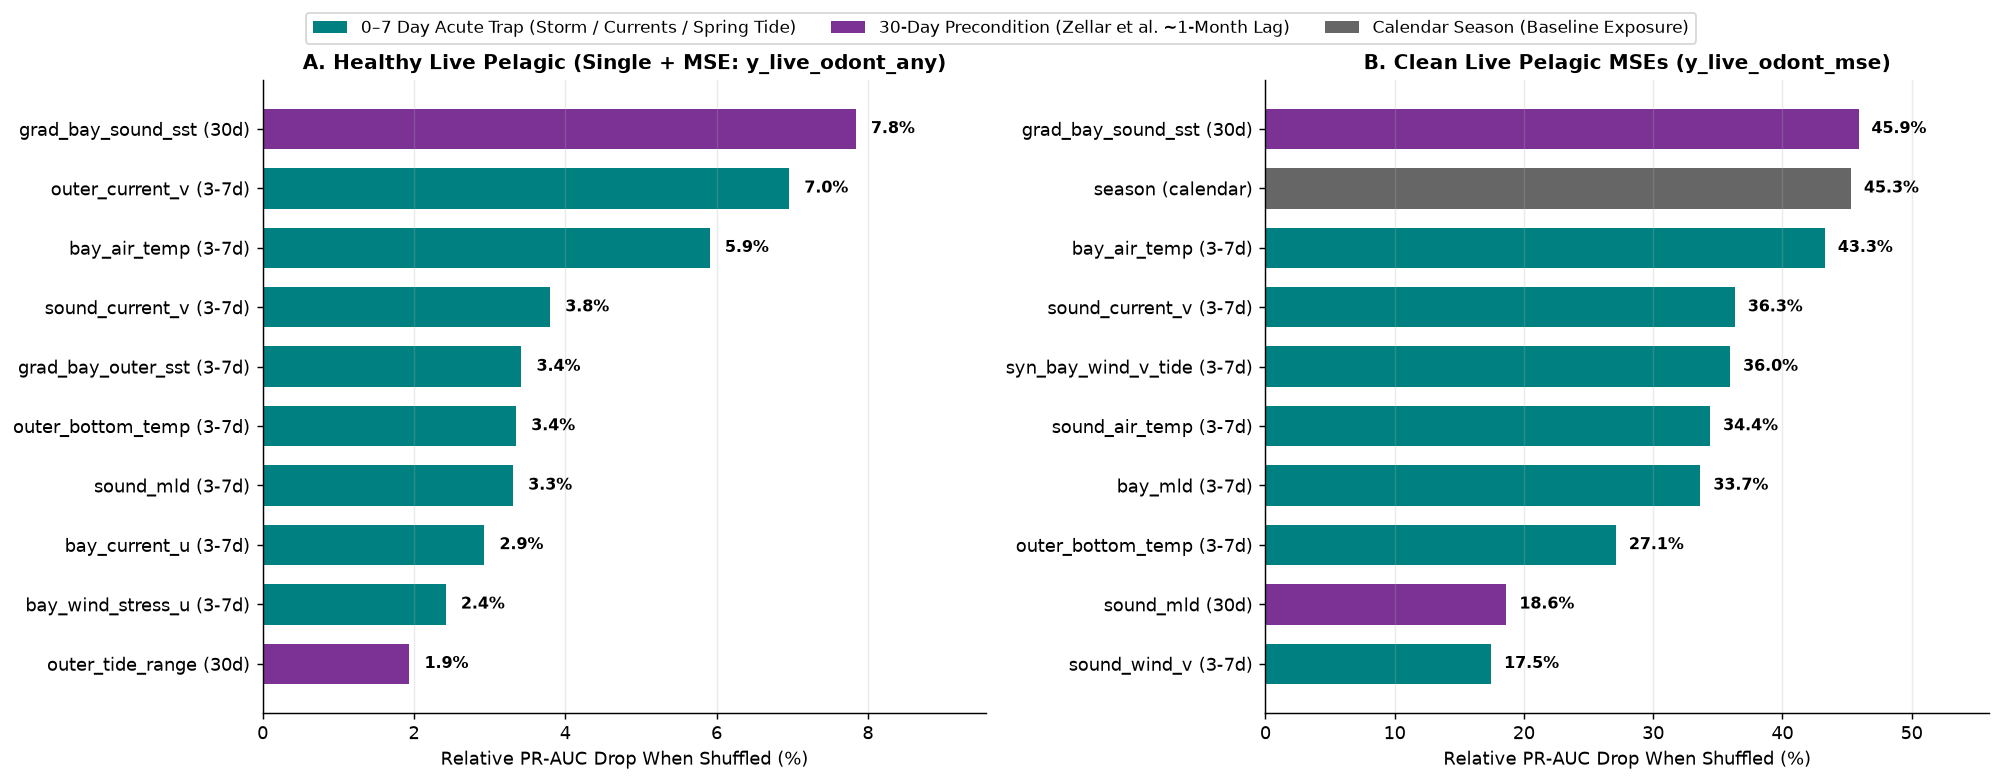

In [10]:
# Load Experiment D ablation and Variable x Timescale permutation importance results
exp_d_ablation_df = pd.read_csv(DATA_DIR / "exp_d_timescale_ablation.csv")
exp_d_perm_df = pd.read_csv(DATA_DIR / "exp_d_timescale_permutation.csv")

print("=== 1. Timescale Ablation (30-Day Precondition vs. 0-7 Day Acute Trap) ===")
print(exp_d_ablation_df.to_string(index=False))

print("\n=== 2. Macro Timescale Permutation Drop (%) ===")
print(exp_d_perm_df[exp_d_perm_df.scope == "macro"].to_string(index=False))
